# Hauptachsen finden

Ein verwickeltes System wird einfach, wenn man es in seinen natürlichen Richtungen betrachtet: den Eigenvektoren seiner Kovarianzmatrix. Das Notebook zeigt an echten Daten, dass dieselbe Zerlegung in vier Gebieten unter verschiedenen Namen auftaucht: als Leistungsspektrum und Whitening beim Rauschen der LIGO-Detektoren (danach ist der Chirp von GW150914 zu sehen), als Systematik-Korrektur bei 150 Sternen des Kepler-Teleskops, als PCA und Autoencoder im Machine Learning, als Schmidt-Zerlegung von Quantenzuständen und als volle Kovarianz, die den Fehler der Hubble-Konstante aus Supernovae bestimmt. Die Frage dabei ist immer, welche Achsen Signal sind und welche nur Rauschen. Der Code steht in [`code/principal_axes/`](https://github.com/deltorobarba/science/tree/main/code/principal_axes) (`pca.py` für Zufallsmatrizen und den Autoencoder, `ligo.py` für die Gravitationswellen-Daten, `kepler.py` für die Lichtkurven, `tomography.py` aus `code/reconstruction/` für die Quantenzustände, `pantheon.py` für die Supernovae); hier stehen nur die Auswahl, die Aufrufe und die Bilder.

**Der rote Faden**

Eine einzige Rechnung, die Zerlegung einer Kovarianzmatrix in Hauptachsen $C = V \Lambda V^T$, löst in allen acht Schritten dasselbe Problem: Signal von Rauschen trennen. Das ist eine von drei Arten, Kompliziertes einfach zu machen: Wiederholtes nur einmal rechnen (`symmetries`, die Achsen vor jeder Messung), die wichtigen Richtungen aus den Daten finden (hier, wenn keine Symmetrie sie liefert) und die führenden Terme behalten (`approximation`).

- **Schritt 1, Mathematik:** Auch reines Rauschen hat Achsen. Das Marchenko-Pastur-Band sagt, wie groß sie zufällig werden, und erst darüber ist eine Achse Signal (BBP-Schwelle). Diese Baseline prüft alle folgenden Schritte.
- **Schritte 2 bis 4, LIGO:** Bei stationärem Rauschen sind die Hauptachsen Frequenzen und die Eigenwerte das Leistungsspektrum. Whitening teilt jede Achse durch die Wurzel ihres Eigenwerts; danach liegt das Rauschen wieder im Marchenko-Pastur-Band aus Schritt 1, und der Chirp von GW150914 wird sichtbar.
- **Schritt 5, Kepler:** Die obersten Achsen von 150 Sternen sind die Systematik des Teleskops. Marchenko-Pastur sagt, wie viele es sind; nach ihrem Abzug bleibt der Transit des Planeten Kepler-8 b.
- **Schritt 6, Machine Learning:** Ein linearer Autoencoder lernt dieselbe Ebene wie die PCA und nicht mehr. Das ist die Baseline, die ein nichtlineares Netz schlagen müsste.
- **Schritt 7, Quantenphysik:** Die Schmidt-Zerlegung eines Zustands ist eine Singulärwertzerlegung; die Eigenwerte der reduzierten Dichtematrix sagen, wie viele Achsen ein Zustand braucht.
- **Schritt 8, Kosmologie:** das 2×2-Beispiel der Einführung mit echten Daten. Die gemeinsamen Achsen der Kovarianz von 354 Supernovae sind die Eichung der Durchmusterungen; wer sie weglässt, unterschätzt den Fehler der Hubble-Konstante um 37 %.

Jede Aussage wird an den Daten geprüft statt behauptet: der Weißtest nach dem Whitening, die Transit-Tiefe gegen die Zahl der abgezogenen Achsen, der Autoencoder gegen die PCA, die volle Kovarianz gegen ihre Diagonale.

**Einführung: die Achsen einer Kovarianz**

Ein kleines Beispiel zuerst. Zwei Geräte messen dieselbe Größe, jedes mit eigenem Rauschen der Varianz $\sigma^2$, und beide hängen an derselben Eichung, die mit Varianz $s^2$ schwankt. Die Kovarianzmatrix der beiden Messwerte ist

$$C = \begin{pmatrix} \sigma^2 + s^2 & s^2 \\ s^2 & \sigma^2 + s^2 \end{pmatrix}.$$

Ihre Eigenvektoren sind die Hauptachsen. Die Achse $(1, 1)/\sqrt2$ hat den Eigenwert $\sigma^2 + 2s^2$: Beide Geräte weichen gemeinsam ab, die Eichung mittelt sich nicht weg. Die Achse $(1, -1)/\sqrt2$ hat den Eigenwert $\sigma^2$: In der Differenz fällt die Eichung heraus. Zum Nachrechnen: Die erste Zeile von $C\,(1, 1)^T$ ist $\sigma^2 + s^2 + s^2$. Wer den Mittelwert beider Geräte bildet und nur die Diagonale von $C$ beachtet, gibt die Varianz $(\sigma^2 + s^2)/2$ an; richtig ist $(\sigma^2 + 2s^2)/2$, weil der Mittelwert ganz auf der ersten Achse liegt. Schritt 8 zeigt diesen Effekt an der Hubble-Konstante.

Allgemein zerlegt man $C = V \Lambda V^T$: Die Spalten von $V$ sind die Hauptachsen, die Diagonale von $\Lambda$ enthält die Varianzen entlang dieser Achsen. Drei Rechnungen, die in verschiedenen Gebieten verschiedene Namen tragen, sind dieselbe Rechnung in dieser Basis:

- **PCA** behält die Achsen mit den größten Eigenwerten (Machine Learning, Kompression).
- **Whitening** teilt jede Achse durch $\sqrt{\lambda_i}$, also $x \mapsto \Lambda^{-1/2} V^T x$; danach hat jede Richtung die Varianz 1. Auch $\chi^2 = x^T C^{-1} x = \sum_i (v_i^T x)^2 / \lambda_i$ ist ein Whitening.
- Bei **stationärem Rauschen** hängt $C_{jk}$ nur vom Abstand $j - k$ ab (Toeplitz-Matrix). Dann sind die Hauptachsen Sinus- und Kosinuswellen und die Eigenwerte das Leistungsspektrum, und Whitening heißt: jede Frequenz durch die Wurzel ihres Spektrums teilen.

Bleibt die Frage, wann eine Achse Signal ist. Auch reines Rauschen hat Hauptachsen: Schätzt man die Kovarianz aus $n$ Proben mit $p$ Merkmalen und Varianz $\sigma^2$, streuen die Eigenwerte über das **Marchenko-Pastur**-Band von $\sigma^2(1 - \sqrt\gamma)^2$ bis $\sigma^2(1 + \sqrt\gamma)^2$ mit $\gamma = p/n$. Ein Signal der Stärke $\ell$ tritt erst als eigene Achse aus dem Band, wenn $\ell > \sqrt\gamma$ (BBP-Übergang). Das ist die Baseline, gegen die jede Achse geprüft wird. Die Beispiele des Notebooks und was der Lauf ergab:

| Gebiet (Schritt) | Daten | Achsen | Ergebnis |
|---|---|---|---|
| Mathematik (1) | 1000 Proben mit 200 Merkmalen, simuliert | Rauschen und ein Signal | Signal sichtbar ab ℓ > 0.45 |
| Astrophysik (2 bis 4) | LIGO-Rauschen um GW150914 | 128 Achsen = Frequenzen | nach dem Whitening 8σ-Signal, Chirp von 30 auf 150 Hz |
| Astrophysik (5) | 150 Kepler-Sterne eines CCD-Kanals | 4 gemeinsame Achsen über dem Band | Transit von Kepler-8 b 0.90 % tief |
| Machine Learning (6) | dieselben Sterne | linearer Autoencoder | dieselbe Ebene wie die PCA, nicht besser |
| Quantenphysik (7) | Zustände aus 12 Qubits | Schmidt-Achsen = Singulärwertzerlegung | kritische Ising-Kette: 3 von 64 Achsen |
| Kosmologie (8) | 354 Supernovae (Pantheon+SH0ES) | Kovarianz 354 × 354, Achsen der gemeinsamen Eichung | H₀-Fehler nur mit der Diagonale 37 % zu klein |

In [1]:
import sys
import urllib.request
from pathlib import Path
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()   # lokal liegt das Notebook in experiments/
CODE = ROOT / "code" / "principal_axes"
TOMO = ROOT / "code" / "reconstruction"                       # tomography.py gehört zum Notebook reconstruction
if "google.colab" in sys.modules and not CODE.exists():      # in Colab den Code aus dem Repository holen
    CODE.mkdir(parents=True)
    TOMO.mkdir(parents=True, exist_ok=True)
    for f in ["pca.py", "ligo.py", "kepler.py", "pantheon.py"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/principal_axes/{f}", CODE / f)
    urllib.request.urlretrieve("https://raw.githubusercontent.com/deltorobarba/science/main/code/reconstruction/tomography.py", TOMO / "tomography.py")
sys.path[:0] = [str(CODE), str(TOMO)]      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import pca, ligo, kepler, tomography, pantheon
DATA = Path.cwd() / "data" / "principal_axes"          # Cache für LIGO-, Kepler- und Pantheon-Dateien

**1. Rauschen hat auch Achsen: Marchenko-Pastur und BBP**

Simuliert werden $n = 1000$ Proben mit $p = 200$ Merkmalen aus reinem Rauschen mit Varianz 1, also $\gamma = 0.2$. Dann bekommt eine Richtung $v$ zusätzlich die Varianz $\ell$ (Spiked-Modell), und gemessen wird, wie gut der oberste Eigenvektor $\hat v$ diese Richtung trifft, mit 20 Läufen je $\ell$ von 0.1 bis 2 (`pca.spike_study`). Das ist die Baseline für die echten Daten: Was reines Rauschen an Achsen erzeugt, ist kein Befund.

Links: Obwohl alle 200 wahren Varianzen gleich 1 sind, streuen die geschätzten Eigenwerte von 0.30 bis 2.04, wie es das Marchenko-Pastur-Band von 0.31 bis 2.09 vorhersagt; der größte ist also doppelt so groß wie jede wahre Varianz. Ein Signal mit $\ell = 0.3$ bleibt darin unsichtbar (oberster Eigenwert 2.05, am Rand des Bandes), eines mit $\ell = 1$ tritt mit 2.29 heraus (Theorie für unendlich viele Proben 2.40). Rechts: Unter der Schwelle $\sqrt\gamma = 0.45$ zeigt die oberste Achse in eine zufällige Richtung, ihre Überlappung mit $v$ ist fast null. Darüber wächst sie wie die Theorie $(1 - \gamma/\ell^2)/(1 + \gamma/\ell)$; knapp über der Schwelle streuen die Läufe am stärksten. Mehr Proben senken die Schwelle wie $1/\sqrt n$.

p = 200 Merkmale, n = 1000 Proben, γ = 0.20: Marchenko-Pastur-Band 0.31 bis 2.09, gemessen 0.30 bis 2.04; BBP-Schwelle √γ = 0.45
  Signal ℓ = 0.3: oberster Eigenwert 2.05 (Theorie 2.09)
  Signal ℓ = 1.0: oberster Eigenwert 2.29 (Theorie 2.40)


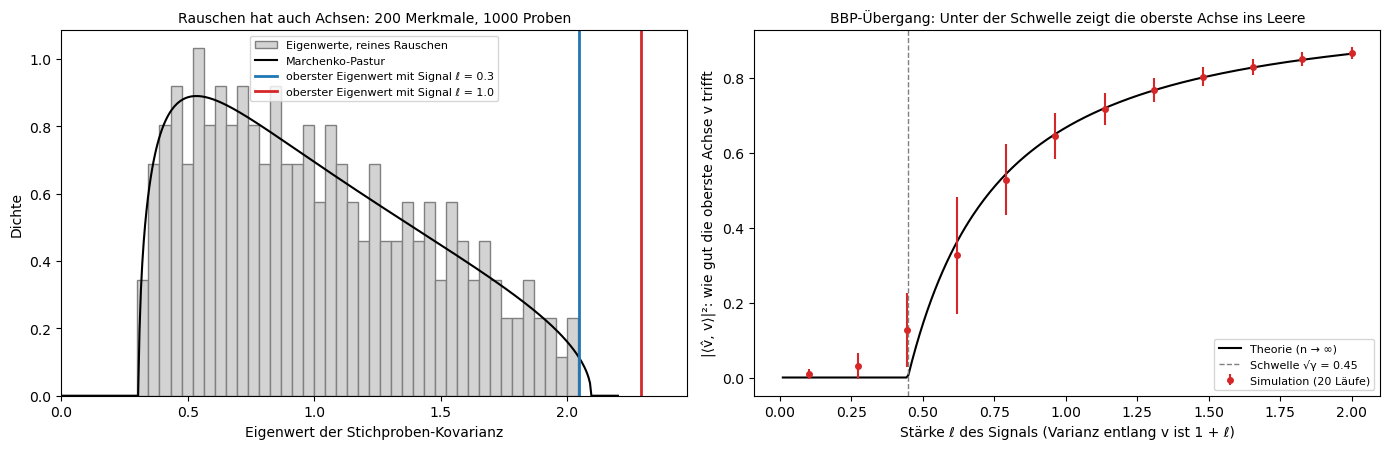

In [2]:
P, N = 200, 1000                         # Merkmale, Proben
SPIKES = np.linspace(0.1, 2.0, 12)       # Stärke ℓ des Signals
pca.spike_study(P, N, SPIKES, trials=20, show=(0.3, 1.0))

**2. LIGO: Die Hauptachsen des Rauschens sind Frequenzen**

Geladen werden die öffentlichen 32 s beider LIGO-Detektoren um GW150914 (Gravitational Wave Open Science Center, 4096 Hz, `ligo.load`). Das Rauschen von Hanford ohne die 2 s um das Ereignis wird in Abschnitte zu 128 Samples (31 ms) geschnitten, und ihre 128 × 128-Kovarianz wird in Hauptachsen zerlegt (`ligo.plot_axes`). Ist das Rauschen stationär, müssen die Achsen Sinuswellen sein und die Eigenwerte das Leistungsspektrum; zum Vergleich dient das Spektrum nach Welch.

**Begriffe**
- **Strain:** die relative Längenänderung der 4 km langen Arme eines Detektors, typisch $10^{-21}$; das Rauschen ist hier bei $2 \cdot 10^{-19}$.
- **stationär:** Die Statistik des Rauschens hängt nicht vom Zeitpunkt ab. Dann hängt die Kovarianz zweier Samples nur von ihrem Abstand ab (Toeplitz-Matrix).
- **Welch-Spektrum:** das Leistungsspektrum, gemittelt über viele kurze, überlappende Abschnitte; es sagt, wie viel Rauschen bei jeder Frequenz liegt.

Links: Die beiden stärksten Achsen sind das tieffrequente Rauschen bei 20 und 36 Hz; in 31 ms passt keine ganze Schwingung davon, deshalb erscheinen sie als Gerade und als Bogen. Die Achsen 3 und 4 sind ein Kosinus und ein Sinus bei 996 Hz, eine schmale Linie im Spektrum. Rechts liegt jeder Eigenwert bei der Frequenz seiner Achse auf dem Welch-Spektrum (Verhältnis im Median 0.94, die mittlere Hälfte zwischen 0.84 und 1.05), über sieben Größenordnungen: vom Rauschen unter 30 Hz über das Minimum zwischen 100 und 300 Hz bis zu den schmalen Linien um 330, 500, 1000 und 1460 Hz (Eichsignale und Eigenschwingungen der Spiegelaufhängungen). Die Streuung um 1 ist die aus Schritt 1: 894 Abschnitte für 128 Merkmale, also $\gamma = 0.14$. Mit Livingston statt Hanford (ausprobiert) ist das Verhältnis im Median 0.89.

GW150914: 2 Detektoren, je 32 s mit 4096 Hz; Strain streut um 2.2e-19
894 Abschnitte zu 128 Samples (31 ms), Kovarianz 128 × 128
Oberste Achsen bei 20 Hz, 36 Hz, 996 Hz, 996 Hz, 1476 Hz, 1476 Hz, 1452 Hz, 1452 Hz
Eigenwert / (Spektrum · fs/2) an der Frequenz der Achse: Median 0.94, mittlere Hälfte 0.84 bis 1.05


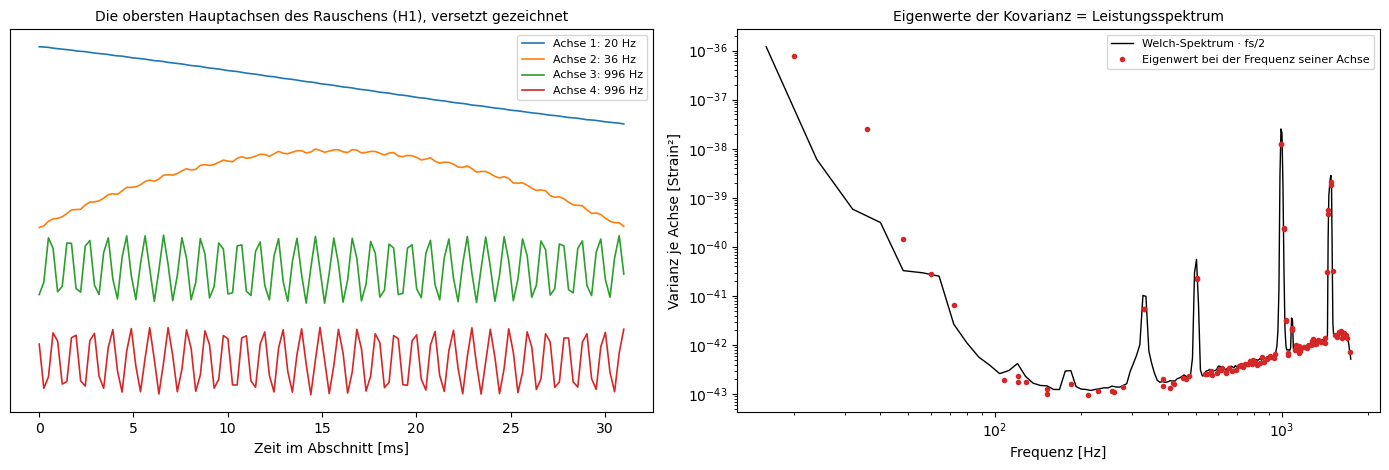

In [3]:
data, fs, t = ligo.load(DATA / "ligo")   # 2 Dateien, zusammen etwa 2 MB
LENGTH = 128                              # Samples je Abschnitt (31 ms bei 4096 Hz)
ligo.plot_axes(data["H1"], fs, t, length=LENGTH)

**3. Whitening: GW150914 aus dem Rauschen holen**

Whitening teilt jede Hauptachse durch die Wurzel ihres Eigenwerts. Nach Schritt 2 heißt das bei stationärem Rauschen: jede Fourier-Komponente durch $\sqrt{S(f)\,f_s/2}$ teilen, mit dem Welch-Spektrum $S$ aus Abschnitten von 4 s (`ligo.whiten`). Danach folgt ein Bandpass von 35 bis 350 Hz, wo das Signal liegt. Als Probe wird die Kovarianz des geweißten Rauschens wieder zerlegt: Ist es weiß, liegen ihre Eigenwerte im Marchenko-Pastur-Band aus Schritt 1.

Oben der rohe Strain von Hanford: eine langsame Schwingung mit etwa 4·10⁻¹⁹ Ausschlag, das tieffrequente Rauschen aus Schritt 2; ein Signal ist nicht zu sehen. Unten nach Whitening und Bandpass: der Chirp von GW150914, in Hanford 8.1 und in Livingston 7.1 Standardabweichungen des Rauschens hoch. Livingston sieht das Signal 7.3 ms früher und mit umgekehrtem Vorzeichen, weil die Detektoren 3000 km auseinander liegen und ihre Arme gegeneinander gedreht sind. Der Weißtest bestätigt das Whitening: Die Eigenwerte des geweißten Rauschens liegen zwischen 0.37 und 1.90, im Marchenko-Pastur-Band von 0.35 bis 1.99. Whitening macht also aus dem farbigen Rauschen das reine Rauschen aus Schritt 1, und davon hebt sich das Signal ab.

Weißtest (H1): Eigenwerte der Kovarianz nach dem Whitening 0.37 bis 1.90, Marchenko-Pastur für weißes Rauschen 0.35 bis 1.99 (γ = 0.17)
  H1: größter Ausschlag 8.1 σ des Rauschens
  L1: größter Ausschlag 7.1 σ des Rauschens
  L1 kommt 7.3 ms früher an, mit umgekehrtem Vorzeichen (Korrelation 0.55)


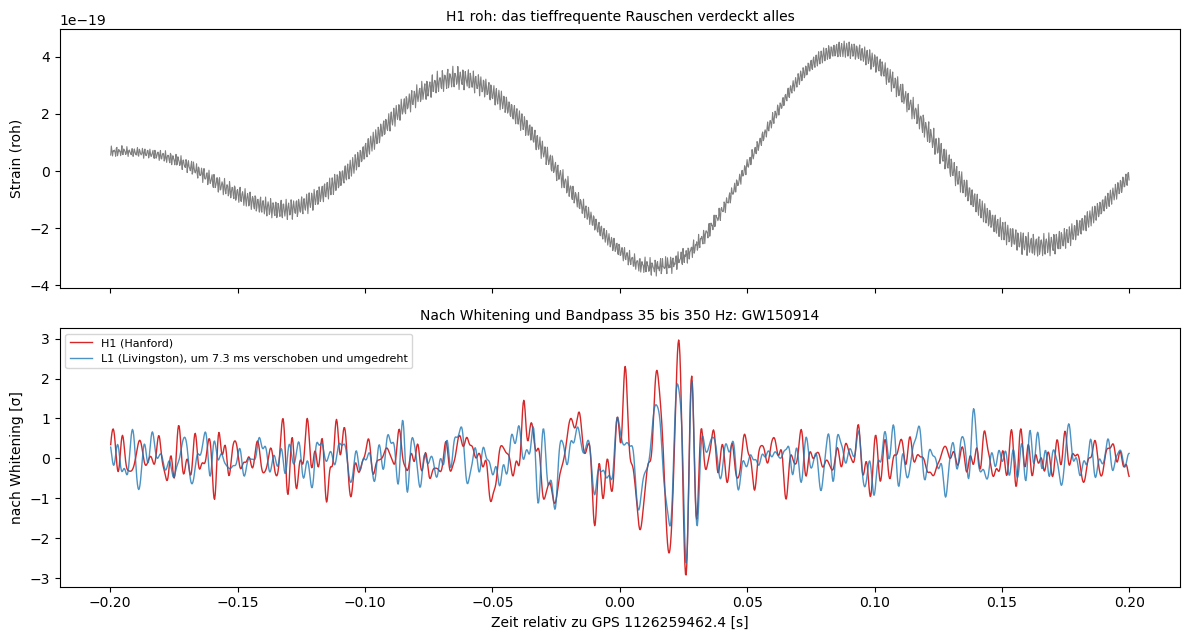

In [4]:
LOW, HIGH = 35, 350                       # Bandpass [Hz], in dem der Chirp liegt
ligo.plot_whitening(data, fs, t, lo=LOW, hi=HIGH)

**4. Der Chirp: Frequenz gegen Zeit**

Um den Chirp zu sehen, wird das geweißte Signal aus Schritt 3 in kurze Wellenpakete mit jeweils etwa acht Schwingungen zerlegt, für 120 Frequenzen von 20 bis 512 Hz (`ligo.plot_chirp`, eine Morlet-Wavelet-Zerlegung wie die Q-Transformation von LIGO). Die Energie jedes Pakets wird durch ihren Median im ruhigen Rauschen geteilt, 1 ist also typisches Rauschen. Darüber liegt die Newtonsche Chirp-Kurve $f(\tau) = \frac{1}{\pi}\left(\frac{5}{256\,\tau}\right)^{3/8}\left(\frac{G\mathcal{M}}{c^3}\right)^{-5/8}$, wobei $\tau$ die Zeit bis zur Verschmelzung ist. Als Chirp-Masse $\mathcal{M}$ dienen 31 Sonnenmassen, wie sie im Detektor erscheint: 28.6 im Ruhesystem der Quelle laut GWTC-1, mal $1 + z = 1.09$.

**Begriffe**
- **Chirp:** das Signal zweier umeinander kreisender Massen, deren Frequenz und Amplitude bis zur Verschmelzung immer schneller steigen.
- **Chirp-Masse** $\mathcal{M}$: die Kombination $(m_1 m_2)^{3/5}/(m_1 + m_2)^{1/5}$ der beiden Massen, die den Frequenzverlauf bestimmt.
- **Zeit-Frequenz-Bild:** zeigt, welche Frequenzen wann vorkommen; jedes Pixel ist die Energie eines kurzen Wellenpakets.

In beiden Detektoren steigt eine helle Spur in etwa 0.2 s von gut 30 Hz auf rund 150 Hz an: das Zwitschern, das dem Chirp den Namen gibt. Ihre größte Energie ist in Hanford 78-mal und in Livingston 45-mal so groß wie das Rauschen, 22 und 17 ms nach dem Bezugszeitpunkt; Livingston liegt wie in Schritt 3 vorn. 0.1 s und 0.05 s vor dem Maximum liegt die Spur in Hanford bei 38 und 49 Hz, in Livingston bei 40 und 52 Hz, die Newtonsche Kurve bei 42 und 54 Hz. Die Formel gilt für zwei weit getrennte Massen; in den letzten Hundertstelsekunden, beim Verschmelzen, versagt sie, und nach dem Maximum bricht die Spur ab. Aus diesem Frequenzverlauf hat die LIGO-Kollaboration 2016 eine erste Chirp-Masse von etwa 30 Sonnenmassen abgeschätzt. Sichtbar wird er erst, weil das Whitening jede Hauptachse des Rauschens auf dieselbe Varianz gebracht hat.

H1: größte Energie 78-mal das Rauschen bei 150 Hz, t = +22.1 ms; 0.1 s und 0.05 s davor bei 38 und 49 Hz (Newton mit 31 Sonnenmassen: 42 und 54 Hz)


L1: größte Energie 45-mal das Rauschen bei 159 Hz, t = +16.7 ms; 0.1 s und 0.05 s davor bei 40 und 52 Hz (Newton mit 31 Sonnenmassen: 42 und 54 Hz)


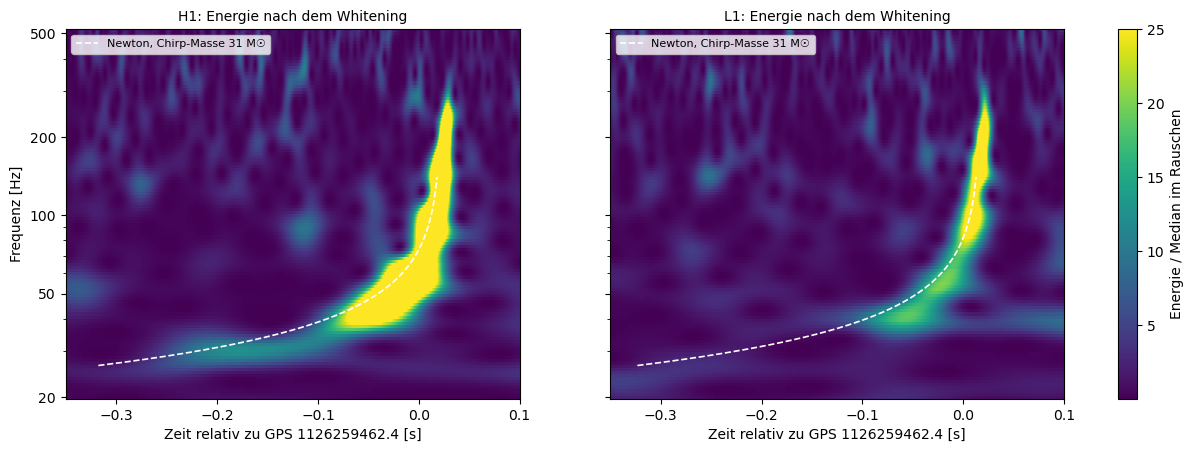

In [5]:
MCHIRP = 31                               # Chirp-Masse im Detektor [Sonnenmassen], nur für die Vergleichskurve
ligo.plot_chirp(data, fs, t, mchirp=MCHIRP)

**5. Kepler: die gemeinsame Systematik vieler Sterne**

Das Kepler-Teleskop sah alle Sterne durch dieselbe Optik und Elektronik; Temperatur, Fokus und Ausrichtung verändern deshalb alle Sterne eines CCD-Kanals gleichzeitig. Geladen werden aus dem MAST-Archiv die rohen Lichtkurven (SAP-Fluss) von Kepler-8 und den 150 hellsten anderen Sternen auf seinem Kanal im ersten Quartal, 33 Tage mit Werten alle 30 Minuten (`kepler.channel_stars`, `kepler.download`). Zerlegt wird die Korrelationsmatrix der 150 Sterne; ihre obersten Zeitachsen werden an Kepler-8 angepasst und abgezogen (`kepler.study`). Der Transit des Planeten Kepler-8 b gehört nur diesem einen Stern und sollte deshalb in keiner gemeinsamen Achse stecken. So arbeitet auch die Pipeline der Mission, mit Cotrending Basis Vectors aus einer Singulärwertzerlegung.

**Begriffe**
- **SAP- und PDCSAP-Fluss:** SAP ist das rohe Licht in der Apertur um den Stern; PDCSAP ist die Kurve der Kepler-Pipeline, schon um gemeinsame Achsen korrigiert.
- **Korrelationsmatrix:** die Kovarianz, nachdem jeder Stern auf Mittel 0 und Streuung 1 gebracht wurde; so zählt jeder Stern gleich.
- **Participation Ratio:** wie viele Sterne eine Achse tragen. Eine Drift des ganzen Kanals betrifft alle, die eigene Schwankung eines Sterns nur einen.
- **Transit-Tiefe:** wie stark der Stern dunkler wird, wenn der Planet vor ihm vorbeizieht; etwa das Quadrat des Radienverhältnisses.

Oben links: Eine Achse trägt 124 der 150 Einheiten Varianz und wird von etwa 134 Sternen getragen (Participation Ratio), eine Drift des ganzen Kanals. Drei weitere Achsen (2.8, 2.5 und 2.3) liegen über der Marchenko-Pastur-Kante 1.73 und werden von Gruppen aus 9 bis 10 Sternen getragen; darunter beginnt das Band. Oben rechts die vier Zeitachsen. Unten links fällt die rohe Lichtkurve von Kepler-8 über das Quartal um 3 %, und die gefaltete Transit-Tiefe ist mit 0.49 % falsch. Nach Abzug der vier Achsen ist die Kurve flach, der Transit 0.90 % tief und die Streuung in 6.5-h-Mitteln 239 ppm; zum Vergleich gibt $R_p/R_\star = 0.0958$ aus dem NASA Exoplanet Archive $(R_p/R_\star)^2$ = 0.92 %. Die Ausgabe zeigt die Wahl der Zahl $k$: Mit 1 bis 20 Achsen bleibt die Tiefe bei 0.90 %, mit 40 Achsen frisst die Korrektur einen Teil des Transits (0.82 %), und die Streuung steigt wieder; das ist Überanpassung. Die Pipeline (PDCSAP) gibt 0.88 % bei 304 ppm; sie lässt die eigene langsame Variabilität des Sterns mit Absicht stehen. Ein zweiter Test mit TrES-2 auf Kanal 33 (ausprobiert) fand 6 Achsen über der Kante, aber dort war schon $k = 1$ am besten: Jede Achse, die nur wenige Sterne tragen, bringt deren Rauschen mit. Marchenko-Pastur sagt, wie viele Achsen gemeinsam sind, nicht wie viele man von jedem Stern abziehen sollte; die Pipeline wägt deshalb jede Achse mit einem Prior.

KIC 6922244 liegt in Quartal 1 auf CCD-Kanal 3; dort 365 Sterne mit Kepler-Helligkeit 10 bis 13.5, genommen die 150 hellsten


150 von 150 Lichtkurven vorhanden (0 s; Cache kepler/)
1 von 1 Lichtkurven vorhanden (0 s; Cache kepler/)


150 Sterne × 1508 gemeinsame Zeitpunkte (von 1639); Streuung je Stern im Median 2 801 ppm
Korrelationsmatrix 150 × 150: oberste Eigenwerte 123.88, 2.77, 2.49, 2.29, 1.45, 1.37; Marchenko-Pastur-Kante 1.73, darüber 4 Achsen
  getragen von etwa 134, 9, 9, 10 Sternen (Participation Ratio)
Kepler-8: Transit-Tiefe und Streuung (6.5-h-Mittel) nach Abzug von k Achsen
  k =  0: Tiefe 0.491%, Streuung  9134 ppm
  k =  1: Tiefe 0.898%, Streuung   306 ppm
  k =  2: Tiefe 0.899%, Streuung   295 ppm
  k =  4: Tiefe 0.898%, Streuung   239 ppm   ← Marchenko-Pastur
  k =  8: Tiefe 0.901%, Streuung   245 ppm
  k = 20: Tiefe 0.897%, Streuung   244 ppm
  k = 40: Tiefe 0.823%, Streuung   312 ppm
  Pipeline (PDCSAP): Tiefe 0.883%, Streuung   304 ppm


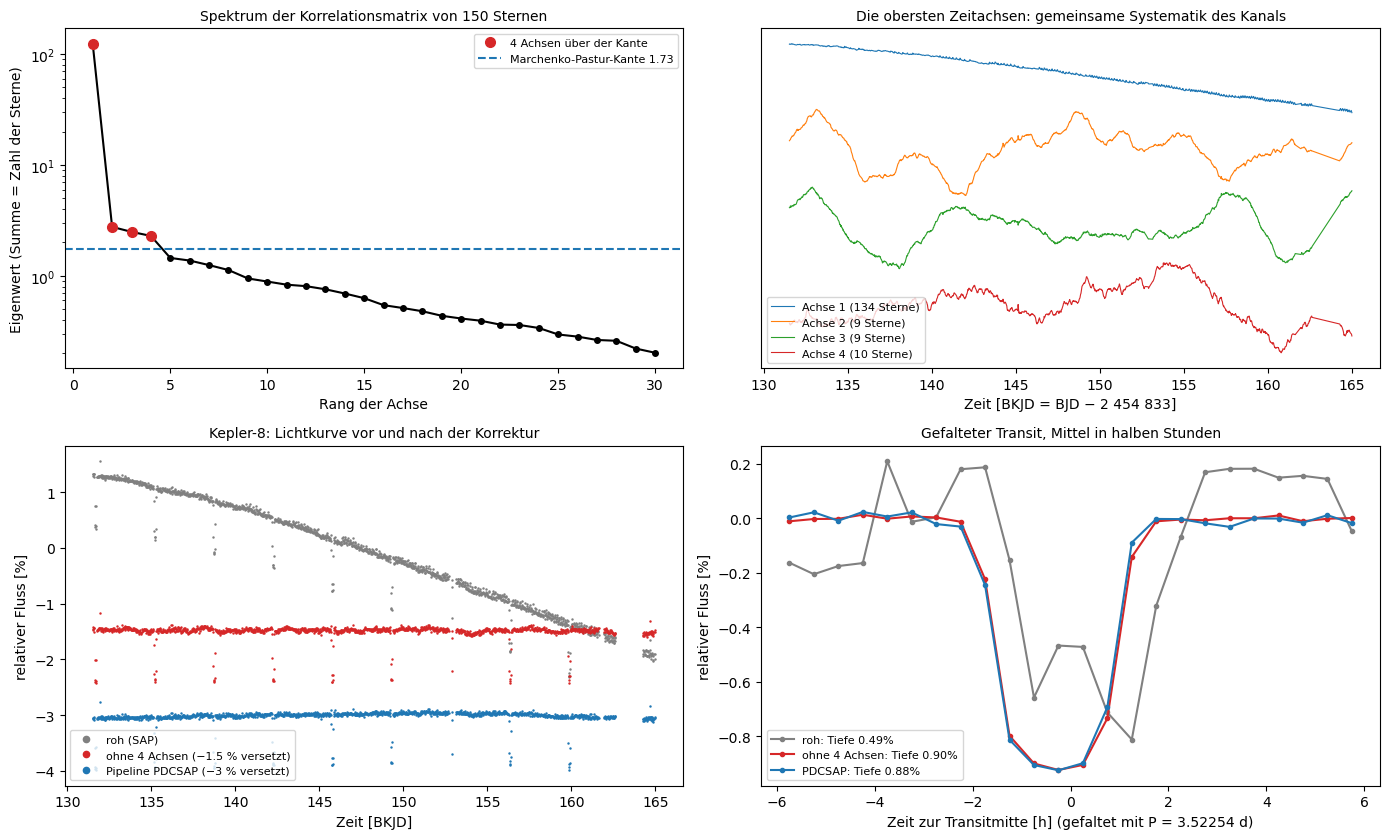

In [6]:
KIC, QUARTER, PERIOD = 6922244, 1, 3.52254      # Kepler-8, erstes Quartal, Periode von Kepler-8 b [d]
N_STARS = 150                                    # hellste Sterne auf demselben CCD-Kanal
target, stars = kepler.channel_stars(KIC, QUARTER, DATA / "kepler", n=N_STARS)
paths = kepler.download(stars, DATA / "kepler")  # beim ersten Lauf etwa 30 MB
t_k, X, y, pdc = kepler.matrix(kepler.download([target], DATA / "kepler")[0], paths)
ev, Vt, K = kepler.study(t_k, X, y, pdc, PERIOD)

**6. Machine Learning: Ein linearer Autoencoder findet dieselbe Ebene**

Ein Autoencoder lernt, Daten durch einen Engpass zu pressen und wiederherzustellen. Mit linearen Schichten und quadratischem Fehler ist das dieselbe Aufgabe wie die PCA (Baldi und Hornik, 1989). Als Baseline-Probe wird er auf die Sterne aus Schritt 5 angesetzt: Jeder Zeitpunkt ist eine Probe mit 150 Merkmalen, der Engpass hat so viele Neuronen, wie Achsen über der Marchenko-Pastur-Kante liegen. Trainiert wird mit Adam auf den ersten 70 % der Zeitpunkte, getestet auf den letzten 30 %, also außerhalb des Trainingsbereichs (`pca.autoencoder_study`).

Links erreicht der Fehler des Autoencoders nach 141 Schritten das PCA-Optimum bis auf 1 % und bleibt dort, auch wenn Adam gelegentlich kurz ausschlägt: Beide erklären im Training 78.8 % und im Test 89.9 % der Varianz. Die Kosinusse der Hauptwinkel zwischen den beiden Unterräumen sind alle 1.0000, der Autoencoder hat genau die Ebene der PCA gefunden. Rechts sieht man aber, dass seine einzelnen Achsen anders liegen: Jede Autoencoder-Achse mischt mehrere PCA-Achsen, denn der Fehler hängt nur von der Ebene ab, nicht von den Pfeilen darin. Die Probe zeigt, wo die Messlatte liegt: Erst ein nichtlineares Netz könnte mehr als die PCA schaffen. Mit TrES-2 und 6 Achsen war es genauso (Test 74.9 % gegen 74.8 %).

150 Merkmale, Training 1055 Proben, Test 453 spätere Proben, Engpass k = 4
  Training: PCA erklärt 78.8% der Varianz, Autoencoder 78.8% (nach 3000 Schritten)
  Test:     PCA 89.9%, Autoencoder 89.9%
  Kosinus der Hauptwinkel zwischen den Unterräumen: 1.0000, 1.0000, 1.0000, 1.0000


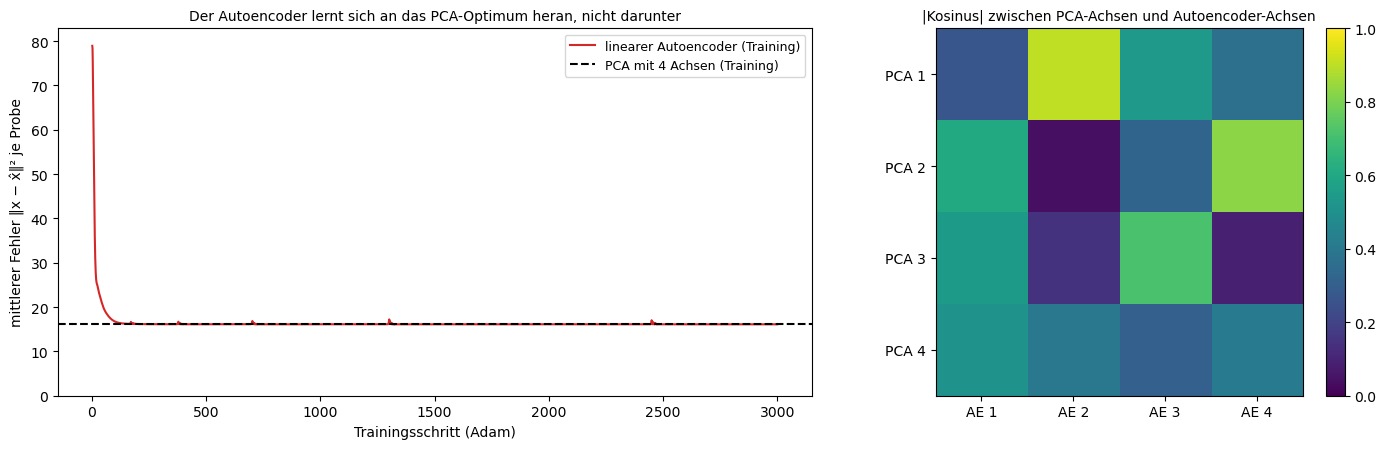

In [7]:
Z = ((X - X.mean(1, keepdims=True)) / X.std(1, keepdims=True)).T   # Zeitpunkte × Sterne, je Stern Streuung 1
W_pca, D_ae = pca.autoencoder_study(Z, k=K, train_frac=0.7, steps=3000)

**7. Quantenzustände: Die Schmidt-Zerlegung ist eine Singulärwertzerlegung**

Teilt man 12 Qubits in zwei Hälften A und B, lässt sich der Zustand als Matrix $M$ schreiben, mit einer Zeile für jeden der 64 Basiszustände von A und einer Spalte für jeden der 64 von B. Ihre Singulärwertzerlegung ist die Schmidt-Zerlegung $\vert\psi\rangle = \sum_i s_i\,\vert a_i\rangle\vert b_i\rangle$, und die $s_i^2$ sind die Eigenwerte der reduzierten Dichtematrix $\rho_A = M M^\dagger$, der Kovarianz des Zustands: Die Schmidt-Achsen sind seine Hauptachsen. Verglichen werden die Grundzustände der Ising-Kette (wie in `reconstruction.ipynb`) mit starkem Feld und am kritischen Punkt, ein GHZ-Zustand und ein zufälliger Zustand (`tomography.schmidt_study`).

**Begriffe**
- **Schmidt-Zerlegung:** $\vert\psi\rangle = \sum_i s_i\,\vert a_i\rangle\vert b_i\rangle$, die Singulärwertzerlegung des Zustands über einen Schnitt; die $s_i^2$ addieren sich zu 1.
- **Reduzierte Dichtematrix** $\rho_A$: der Zustand der Hälfte A allein; ihre Eigenwerte sind die $s_i^2$.
- **Verschränkungsentropie:** $-\sum_i s_i^2 \ln s_i^2$; 0 für einen Produktzustand, ln 64 = 4.16, wenn alle 64 Achsen gleich schwer sind.

Links das Schmidt-Spektrum, rechts das behaltene Gewicht gegen die Zahl der Achsen, wie die erklärte Varianz einer PCA. Mit starkem Feld ($h = 3J$) steht fast jeder Spin in Feldrichtung, der Zustand ist beinahe ein Produktzustand: Entropie 0.043, zwei Achsen tragen 99.9 %. Am kritischen Punkt ist die Entropie 0.397 und drei Achsen genügen; die ersten beiden tragen 87 und 13 %, danach fallen die Gewichte etwa um das Hundertfache je zwei Achsen, ab Achse 10 liegen sie unter 10⁻¹⁰. Der GHZ-Zustand hat genau zwei gleich schwere Achsen (Entropie ln 2 = 0.693). Der zufällige Zustand verteilt sein Gewicht fast gleichmäßig: Entropie 3.65, nahe am Höchstwert ln 64 = 4.16 und an der Erwartung ln 64 − ½ = 3.66 für zufällige Zustände (Page, 1993); 58 von 64 Achsen sind nötig. Grundzustände lokaler Hamiltonoperatoren in einer Dimension sind also über jeden Schnitt „niedrigrangig“. Darauf beruhen Matrixproduktzustände und DMRG, die nur die obersten Schmidt-Achsen behalten. Auf einem Quantencomputer ließen sich die Hauptachsen einer Dichtematrix mit Quanten-PCA aus vielen Kopien des Zustands gewinnen (Lloyd, Mohseni und Rebentrost, 2014).

12 Qubits, Schnitt in der Mitte: höchstens 64 Schmidt-Achsen, größte mögliche Entropie ln 64 = 4.16
  Ising h = 3 J (Feld überwiegt)   Entropie 0.043;  2 Achsen tragen 99.9% des Gewichts
  Ising h = J (kritisch)           Entropie 0.397;  3 Achsen tragen 99.9% des Gewichts
  GHZ                              Entropie 0.693;  2 Achsen tragen 99.9% des Gewichts
  zufälliger Zustand               Entropie 3.651; 58 Achsen tragen 99.9% des Gewichts


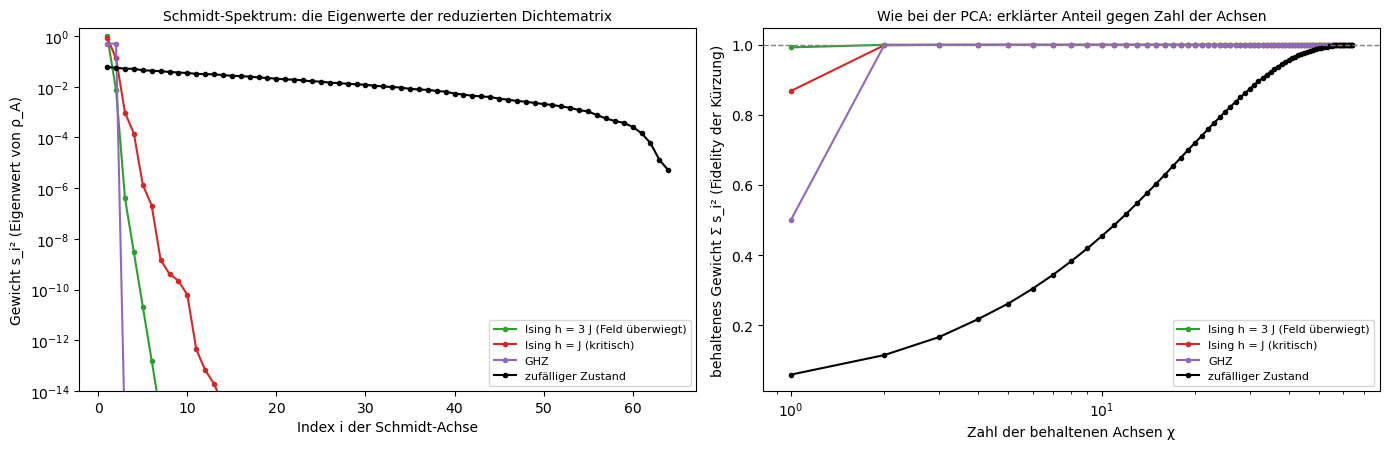

In [8]:
Q = 12                                           # Qubits; Schnitt in der Mitte gibt eine 64 × 64-Matrix
states = {"Ising h = 3 J (Feld überwiegt)": tomography.ising_ground_state(Q, h=3.0),
          "Ising h = J (kritisch)": tomography.ising_ground_state(Q, h=1.0),
          "GHZ": tomography.ghz_state(Q), "zufälliger Zustand": tomography.random_pure_state(Q, seed=0)}
tomography.schmidt_study(Q, states, keep=0.999)

**8. Pantheon+: kleine gemeinsame Fehler, großer Effekt auf H₀**

Zurück zum 2×2-Beispiel der Einführung, jetzt mit echten Daten. Pantheon+ hat die Helligkeit von 1701 Lichtkurven von Supernovae vom Typ Ia veröffentlicht, mit der vollen Kovarianzmatrix aus Messrauschen und gemeinsamen Fehlern (33 MB, `pantheon.load`). Die Hubble-Konstante H₀ entsteht daraus in zwei Stufen: 77 Kalibratoren in 37 Galaxien, deren Entfernung aus Cepheiden bekannt ist, eichen die absolute Helligkeit $M_B$, und 277 Supernovae im Hubble-Fluss übersetzen sie in H₀. Angepasst werden beide Parameter mit verallgemeinerten kleinsten Quadraten, einmal mit der vollen Kovarianz und einmal nur mit ihrer Diagonale; außerdem wird die Korrelationsmatrix in Hauptachsen zerlegt (`pantheon.study`).

**Begriffe**
- **Supernova vom Typ Ia:** ein explodierender Weißer Zwerg mit fast immer gleicher Leuchtkraft, eine Standardkerze: Aus der scheinbaren Helligkeit folgt die Entfernung.
- **Hubble-Fluss:** Galaxien, die so weit weg sind (hier z von 0.023 bis 0.149), dass die Expansion ihre Eigenbewegung überwiegt; dort gilt Geschwindigkeit = H₀ · Entfernung.
- **Verallgemeinerte kleinste Quadrate:** $\chi^2 = r^T C^{-1} r$ statt $\sum_i r_i^2/\sigma_i^2$; in der Eigenbasis $\sum_i (v_i^T r)^2/\lambda_i$, ein Whitening wie in Schritt 3.
- **Durchmusterung:** eine Beobachtungskampagne mit eigener Kamera und Eichung; alle ihre Supernovae teilen deren Fehler.

Zwei Supernovae sind im Mittel nur mit 0.003 korreliert, aus derselben Durchmusterung mit 0.016 und unter den Kalibratoren mit 0.029; links sieht man die Blöcke. Einzeln ist das wenig, aber es betrifft viele Paare. Für den Mittelwert von $n$ Messungen mit Korrelation $\rho$ wächst die Varianz um den Faktor $1 + (n - 1)\rho$, bei den 77 Kalibratoren also etwa um 1 + 76 · 0.029 = 3.2: Die Unsicherheit ihres Mittelwerts ist mit Korrelationen 0.036 statt 0.022 mag, das 1.66-Fache. In der Mitte haben die obersten Achsen der Korrelationsmatrix die Eigenwerte 9.3 und 7.3 statt 1 und werden von 120 und 134 Supernovae getragen: gemeinsame Eichung, wie die Achse (1, 1)/√2 im 2×2-Beispiel. Rechts das Ergebnis: Mit voller Kovarianz ist H₀ = 73.53 ± 1.05 km/s/Mpc, nahe am veröffentlichten Wert von SH0ES (73.04 ± 1.04); nur mit der Diagonale 73.50 ± 0.66, derselbe Wert mit einem um 37 % zu kleinen Fehler. Der Abstand zu Planck (67.4 ± 0.5) sähe dann nach 7.4σ statt 5.3σ aus: Wer die gemeinsamen Achsen weglässt, überschätzt, wie sicher eine Spannung ist.

Pantheon+SH0ES: 1701 Lichtkurven, Kovarianz 1701 × 1701
77 Kalibratoren und 277 Supernovae im Hubble-Fluss, Kovarianz 354 × 354
Mittlere Korrelation zweier Supernovae: alle 0.003, gleiche Durchmusterung 0.016 (6445 Paare), Kalibratoren untereinander 0.029
  Mittelwert der 77 Kalibratoren: σ = 0.0359 mag mit Korrelationen, 0.0216 ohne (Faktor 1.66)
  Mittelwert der 277 Hubble-Fluss: σ = 0.0122 mag mit Korrelationen, 0.0091 ohne (Faktor 1.34)
Oberste Eigenwerte der Korrelationsmatrix (ohne Korrelation alle 1): 9.3, 7.3, 3.6, 3.4; getragen von 120, 134, 70, 61 Supernovae
  volle Kovarianz  M_B = -19.247 ± 0.030,  H₀ = 73.53 ± 1.05 km/s/Mpc,  Abstand zu Planck 5.3σ
  nur Diagonale    M_B = -19.245 ± 0.018,  H₀ = 73.50 ± 0.66 km/s/Mpc,  Abstand zu Planck 7.4σ


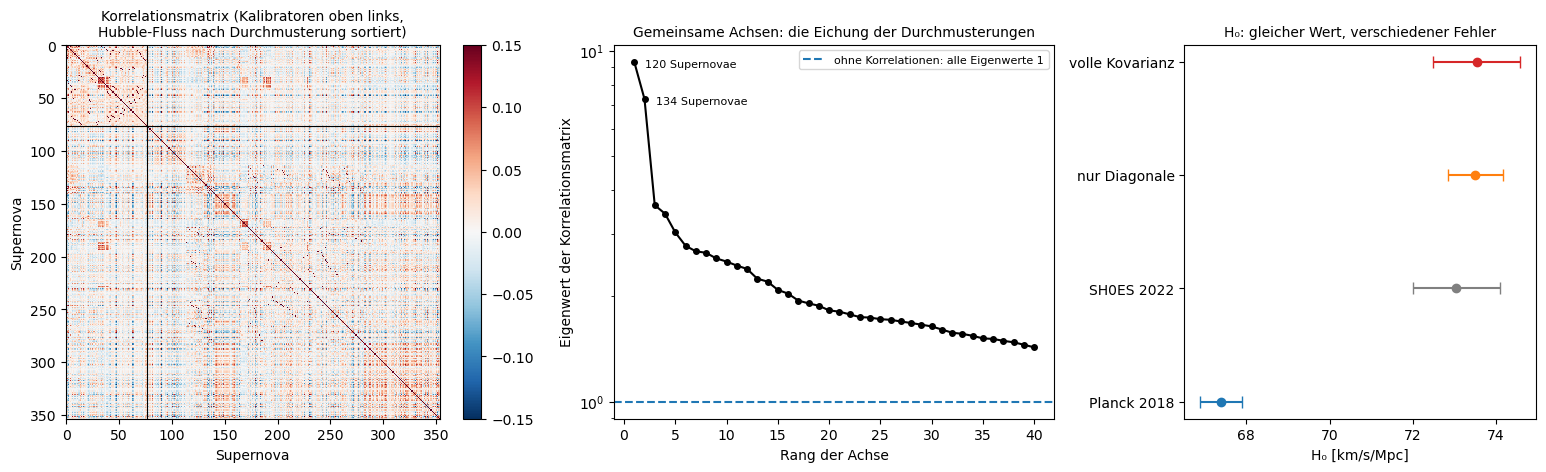

In [9]:
sn, cov = pantheon.load(DATA / "pantheon")     # 2 Dateien, zusammen 34 MB, beim ersten Lauf von GitHub
results = pantheon.study(sn, cov)